# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/wine.csv`
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = PROJECT_DIR / "data" / "wine.csv"

df = pd.read_csv(DATA_PATH)

Forma (filas, columnas): (178, 14)

--- Tipos ---
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

--- Nulos por columna ---
Sin valores nulos
Total de nulos: 0

--- Duplicados ---
Filas duplicadas: 0 (0.00%)

--- Distribución de target ---
        conteo  proporcion
target                    
0           59      0.3315
1           71      0.3989
2           48      0.2697

--- describe() ---


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


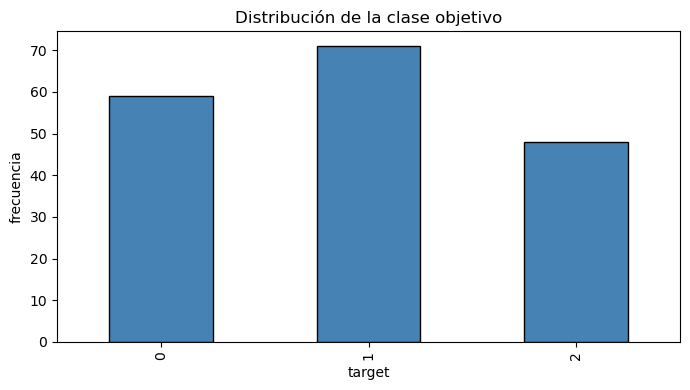

In [4]:
# Profiling básico de df

# Forma
print("Forma (filas, columnas):", df.shape)

# Tipos de datos
print("\n--- Tipos ---")
print(df.dtypes)

# Nulos por columna
print("\n--- Nulos por columna ---")
nulos = df.isna().sum()
print(nulos[nulos > 0] if nulos.any() else "Sin valores nulos")
print("Total de nulos:", int(df.isna().sum().sum()))

# Duplicados
n_dup = df.duplicated().sum()
print("\n--- Duplicados ---")
print("Filas duplicadas:", int(n_dup), f"({n_dup / len(df):.2%})")

# Distribución del target
print("\n--- Distribución de target ---")
conteo = df["target"].value_counts().sort_index()
proporcion = df["target"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"conteo": conteo, "proporcion": proporcion.round(4)}))

# Resumen estadístico
print("\n--- describe() ---")
display(df.describe().T)

# Gráfico de la distribución de clases
ax = conteo.plot(kind="bar", color="steelblue", edgecolor="black")
ax.set_title("Distribución de la clase objetivo")
ax.set_xlabel("target")
ax.set_ylabel("frecuencia")
plt.tight_layout()
plt.show()


**Calidad:**

El dataset tiene 178 filas y 13 variables numéricas (`float64`), más `target`, entero con 3 clases. No hay valores nulos ni filas duplicadas. Aun así, se mantiene un `SimpleImputer` en los pipelines como protección ante datos nuevos incompletos. Las clases están un poco desbalanceadas (0: 33 %, 1: 40 %, 2: 27 %), por lo que el split se hace estratificado. Las escalas de las variables son muy distintas (`proline` en los cientos o miles y `hue` alrededor de 1), por lo que los modelos basados en distancias o en coeficientes necesitarán estandarización.

## 2. Split train/test

In [ ]:
# Split estratificado 80/20
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

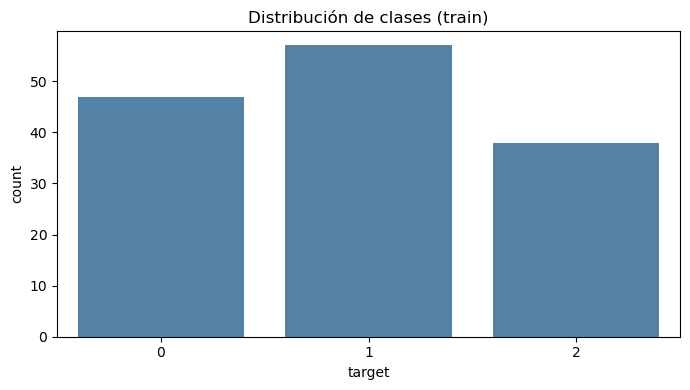

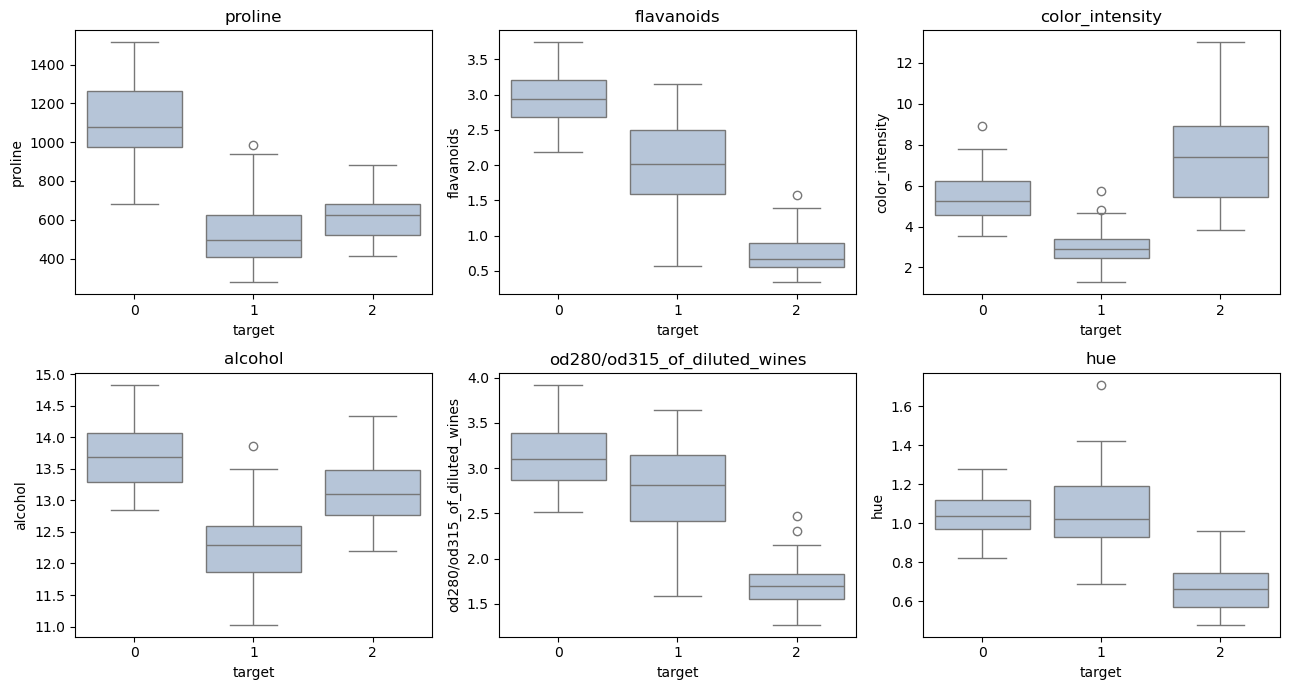

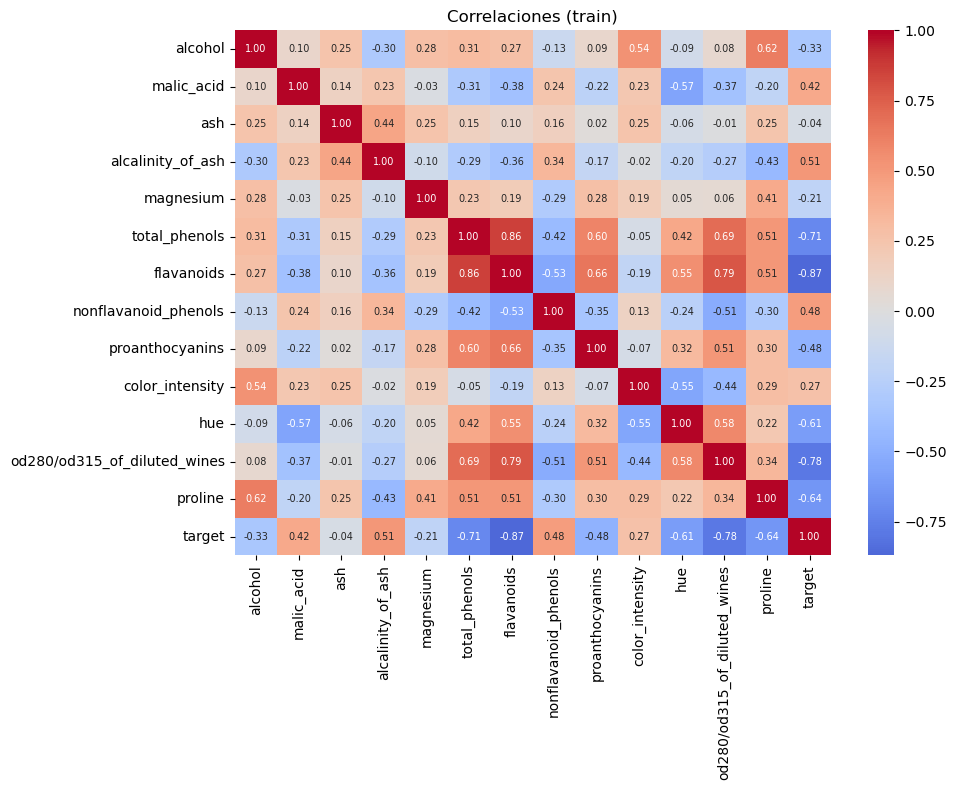

Escalas (rango por variable):
proline                         1237.00
magnesium                         92.00
alcalinity_of_ash                 19.40
color_intensity                   11.72
malic_acid                         5.06
alcohol                            3.80
flavanoids                         3.40
proanthocyanins                    3.16
total_phenols                      2.90
od280/od315_of_diluted_wines       2.65
ash                                1.86
hue                                1.23
nonflavanoid_phenols               0.50
dtype: float64

Medias por clase:


,proline,flavanoids,color_intensity,alcohol,od280/od315_of_diluted_wines,hue
target,,,,,,
0,1092.34,2.93,5.48,13.70,3.14,1.05
1,526.25,2.01,2.98,12.28,2.77,1.05
2,622.89,0.78,7.39,13.11,1.71,0.68


Pares más correlacionados:
flavanoids                    target                          0.870
total_phenols                 flavanoids                      0.861
flavanoids                    od280/od315_of_diluted_wines    0.786
od280/od315_of_diluted_wines  target                          0.784
total_phenols                 target                          0.714
dtype: float64


In [7]:
# EDA usando solamente train_df
features = [c for c in train_df.columns if c != "target"]

# 1. Distribución de clases en entrenamiento
ax = sns.countplot(data=train_df, x="target", color="steelblue")
ax.set_title("Distribución de clases (train)")
plt.tight_layout()
plt.show()

# 2. Boxplots por clase de variables relevantes
relevantes = ["proline", "flavanoids", "color_intensity", "alcohol", "od280/od315_of_diluted_wines", "hue"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), relevantes):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 3. Matriz de correlaciones
corr = train_df[features + ["target"]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlaciones (train)")
plt.tight_layout()
plt.show()

# Apoyo numérico para los hallazgos
print("Escalas (rango por variable):")
print((train_df[features].max() - train_df[features].min()).sort_values(ascending=False).round(2))
print("\nMedias por clase:")
display(train_df.groupby("target")[relevantes].mean().round(2))
pares = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
print("Pares más correlacionados:")
print(pares.head(5).round(3))

**Hallazgos:**

1. **Hay variables muy discriminantes.** `flavanoids` tiene una correlación de 0.87 con el target y separa bien la clase 2 (media 0.78 frente a 2.93 y 2.01). `proline` separa la clase 0 (media de aprox. 1092 frente a 526 y 623), y `color_intensity` distingue la clase 1 (aprox. 2.98) de las otras dos.
2. **Hay colinealidad fuerte entre variables fenólicas.** `total_phenols`–`flavanoids` tienen r = 0.86 y `flavanoids`–`od280/od315` r = 0.79. Aportan información redundante. La regularización de `LogisticRegression` ayuda a controlarlo.
3. **Las escalas son muy heterogéneas.** El rango de `proline` es de aprox. 1237 y el de `nonflavanoid_phenols` de aprox. 0.5. Sin escalar, `proline` dominaría las distancias de KNN y afectaría la optimización de la regresión logística, así que `StandardScaler` es obligatorio para esos modelos (los árboles no lo necesitan). Además, con solo 142 filas de entrenamiento, la validación cruzada tendrá varianza notable entre folds.

## 4. Persistencia de datos y contrato

In [8]:
# Reiniciar índices y guardar los splits sin índice
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

# Contrato de datos para las siguientes etapas
data_contract = {
    "target": "target",
    "features": [c for c in df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
    "n_train": len(train_df),
    "n_test": len(test_df),
    "classes": sorted(int(c) for c in df["target"].unique()),
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(data_contract, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(data_contract, indent=2, ensure_ascii=False))

{
  "target": "target",
  "features": [
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280/od315_of_diluted_wines",
    "proline"
  ],
  "random_state": 42,
  "test_size": 0.2,
  "n_train": 142,
  "n_test": 36,
  "classes": [
    0,
    1,
    2
  ]
}


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.